In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join("..", "hil_bench")))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import analysis as A, params as P, pr_design as D
claims = []
def claim(cid, text, number, source):
    claims.append({"ID": cid, "Claim": text, "Number": number, "Source": source})
NBID = "00"

# 00 · Overview: a reference harmonic emitter on Typhoon HIL

Studies of how much harmonic emission a grid can take (harmonic hosting capacity) usually treat a PV
inverter as an **ideal harmonic current source**: it pushes a fixed current at each harmonic order,
whatever the grid does. A real inverter is a switching bridge with an LCL filter and a controller.
It can only do that within limits.

This repository is an **open reference emitter**: one 100 kVA PV inverter on Typhoon HIL that
injects each harmonic order at a level you choose (up to the IEEE 1547 limit). It was run in Virtual
HIL and on a real **HIL404** at Pulchowk Campus, Institute of Engineering, Tribhuvan University, on 5 Oct 2026. The notebooks show:

- how well it delivers what is asked,
- whether it really behaves like an ideal current source,
- and the three conditions it needs to do so.

Anyone with Typhoon HIL (or the free Virtual HIL) can run it and plug it into their own network.

## The main result in one figure

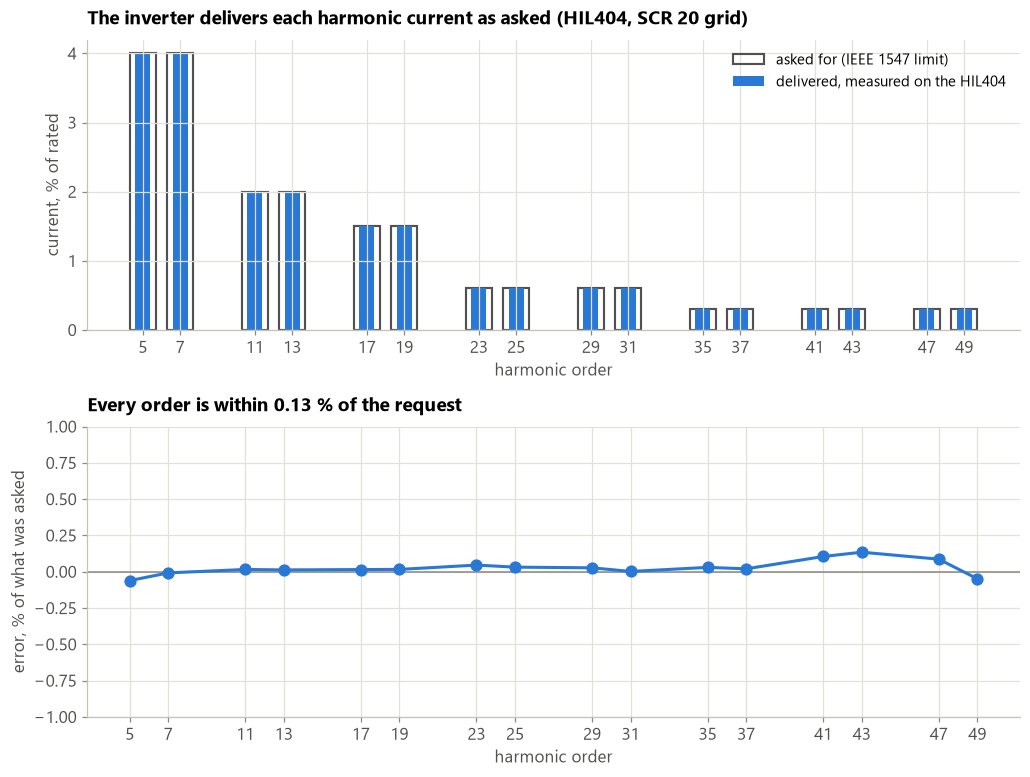

In [2]:
b = A.load("bench_hil404.csv")
x = b[(b.grid == "SCR 20") & (b.order > 1)]
fig, ax = A.panels(2, h=3.6)
ax[0].bar(x.order, x.I_request_pct, width=1.4, color="none", edgecolor=A.LIMIT, lw=1.4, label="asked for (IEEE 1547 limit)")
ax[0].bar(x.order, x.I_pct, width=0.8, color=A.USED, label="delivered, measured on the HIL404")
ax[0].set_ylabel("current, % of rated")
ax[0].set_title("The inverter delivers each harmonic current as asked (HIL404, SCR 20 grid)")
A.orders_axis(ax[0]); ax[0].legend(loc="upper right")
ax[1].axhline(0, color=A.MUTED, lw=1)
ax[1].plot(x.order, x.I_error_pct_of_request, "o-", color=A.USED)
ax[1].set_ylim(-1, 1)
ax[1].set_ylabel("error, % of what was asked")
ax[1].set_title("Every order is within %.2f %% of the request" % x.I_error_pct_of_request.abs().max())
A.orders_axis(ax[1])
A.save(fig, "00_main_result", x[["order", "I_request_pct", "I_pct", "I_error_pct_of_request"]])
claim("C0.1", "On the HIL404 at SCR 20, full IEEE 1547 request, every order is within this error of its request",
      "%.2f %%" % x.I_error_pct_of_request.abs().max(), "results/bench_hil404.csv")

**How to read it.** Top: the grey outline is what we asked for at each harmonic order (the IEEE 1547
limit, in % of rated current); the blue bar is what came out of the real HIL404. They overlap. Bottom:
the difference, in % of what was asked. The y-axis runs from −1 % to +1 % and the dots sit near zero.

## Datasheet

Numbers come from the notebooks that follow. Each row links to its claim ID in `CLAIMS.md`.

| Item | Value | Notebook |
|---|---|---|
| Rating | 100 kVA, 400 V, 50 Hz, DC 750 V (650-1000 V) | 01 |
| Switching / control | 10 kHz, controller every 100 µs, LCL filter | 01 |
| Regulated orders | 5, 7, 11, 13, ..., 47, 49 (16 orders) | 01 |
| What you set | each order 0-100 % of its IEEE 1547 limit, a master scale, grid strength, DC voltage, grid frequency, background 5th/7th | 01 |
| Accuracy (HIL404, settled) | within 0.5 % of the request, every order, stiff to SCR 5 (see the conditions) | 02 |
| Real device vs Virtual HIL | same results: largest THD_V difference over 82 sweep points 0.24 percentage points | 02 |
| Ideal current source? | yes at the regulated orders: V/I at the PCC equals the grid impedance within 0.4 % | 03 |
| Condition 1 | active damping (capacitor-current feedback) - without it, unstable on any real grid | 04 |
| Condition 2 | frequency-adaptive resonators - fixed ones lose most of the high orders 0.25 Hz off 50 Hz | 05 |
| Condition 3 | enough DC voltage: at SCR 5 with full emission, more than about 710 V; wait up to 2 min after a step | 06 |
| Emission vs voltage limits | full emission meets EN 50160 at SCR 20 only; SCR 10 allows 55 %, SCR 5 28 % | 07 |
| Validated on | Virtual HIL (Typhoon 2026.3) and HIL404 (Pulchowk Campus, IOE, Tribhuvan University, 5 Oct 2026) | 02 |

## What this does **not** show

- One inverter only, on a simple R-L grid (X/R = 3 assumed). No cable capacitance, so no network resonance yet.
- Only the 16 regulated orders are controlled. Other frequencies are checked in notebook 03 but not regulated.
- Grid voltage limits are compared with single 10-cycle snapshots, not the week-long statistics EN 50160 uses.
- The stability results (notebook 04) come from a linear model; the HIL runs confirm it ran stably, not the margins.

## Notebooks

| # | Question |
|---|---|
| 01 | What is the emitter? (ratings, filter, request, grids, controller) |
| 02 | Does it deliver what is asked, on the real device and in Virtual HIL? |
| 03 | Is it an ideal current source? |
| 04 | Condition 1: why it needs active damping to stay stable |
| 05 | Condition 2: why it needs frequency-adaptive resonators |
| 06 | Condition 3: how much DC voltage it needs, and how long to wait |
| 07 | What the emission does to grid voltage limits |

In [3]:
c = pd.DataFrame(claims)
c.to_csv(os.path.join(A.FIG, "claims_%s.csv" % NBID), index=False)
display(Markdown(A.md_table(c)))

| ID | Claim | Number | Source |
|---|---|---|---|
| C0.1 | On the HIL404 at SCR 20, full IEEE 1547 request, every order is within this error of its request | 0.13 % | results/bench_hil404.csv |